# 02 综合评价法：TOPSIS 法

> **模块**：综合评价 ｜ **数据**：无（内置示例） ｜ **依赖**：numpy

## 1. 问题背景

当评价对象为单目标时，其评价工作是容易进行的；当评价对象为多目标时，这项工作就困难多了。目标可以细化为指标。可以打这样的比方：在一群人之中要评选个子最高的很容易办到，要评选最胖的也还不难，但要评选一个最高又最胖的，而且是最健康的就不容易了。评价的困难主要有以下两项：
1. 有的指标没有明确的数量表示，甚至只与使用人或评价人的主观感受与经验有关；
2. 不同的方案（也即被评价对象）可能各有所长，指标越多，方案越多，问题就越是复杂。

人们有必要认真研究多目标决策中的排序与择优规律，TOPSIS 法正是在这种背景下产生的一种逼近理想解的排序方法。


## 2. 学习目标

- 掌握 TOPSIS 法的基本思想与适用条件
- 掌握正负理想解与贴近度的计算步骤
- 掌握基于 Python 的 TOPSIS 实现


## 3. 环境与数据

- Jupyter 开发环境
- Python 3.10


## 4. 方法与实现

层次分析法（The analytic hierarchy process，AHP）是一种定性与定量分析相结合的多准则决策方法。这一方法的特点，是在对复杂决策问题的本质、影响因素以及内在关系等进行深入分析之后，构建一个层次结构模型，然后利用较少的定量信息，把决策的思维过程数学化，从而为求解多目标、多准则或无结构特性的复杂决策问题，提供一种简便的决策方法。

### 4.1 明确问题

小明同学想出去旅游，在查阅了网上的攻略后，他初步选择了苏杭、黄山和庐山三地之一作为目标地点。请确定评价指标、形成评价体系来为小明同学选择最佳方案。

评价的指标需要我们自己制定，查询资料后我们选择以下五个指标：
1. 景色
2. 费用
3. 饮食
4. 居住
5. 旅途

### 4.2 构建层次结构

根据以上制定的评价指标，我们可以建立如下图的层次分析结构

> *原稿配图未随 notebook 保存，此处暂缺。*

- 目标层：表示解决问题的目的，即应用AHP所要达到的目标；
- 准则层：实现预定目标所涉及的中间的环节；
- 方案层：表示解决问题的具体方案。

我们要依据喜好对这三个层次相互比较判断，然后进行综合评价在这三个旅游地中哪个为最佳地点。

### 4.3 模型建立与求解

#### 4.3.1 构建判断矩阵

建立层次分析结构之后，我们就可以在各层元素中进行两两比较，构造出比较判断矩阵。

层次分析法主要是人们对每一层次中各因素相对重要性给出的判断，这些判断通过引入适合的标度用数值表示出来，写成判断矩阵。

在层次分析法中，为了使决策判断定量化，形成数值判断矩阵，常根据一定的比率标度将判断定量化，下面给出一种常用的1~9标度方法

> *原稿配图未随 notebook 保存，此处暂缺。*

实际上，凡是较复杂的决策问题，其判断矩阵是经由多位专家（评价者）填写咨询表之后形成的。

以下为两两比较判断法得到的判断矩阵

> *原稿配图未随 notebook 保存，此处暂缺。*

我们可以将得到的判断矩阵设为$A = {(a_{ij})}_{5×5}$ 。

矩阵$A$中的$a_{12}=\frac{1}{2}$表示景色与费用对选择旅游这个目标来说的重要程度之比为1:2（景色比费用稍微不重要），而$a_{21}=2$则表示费用与景色对选择旅游地这个目标来说重要程度之比为2:1（费用比景色稍微重要），以此类推，在进行两两比较时，只需要进行4+3+2+1=10次比较即可。

若一矩阵中元素$a_{ij}>0$且满足$a_{ij}×a_{ji} = 1$，我们就称满足这一条件的矩阵为正互反矩阵，那么以上判断矩阵$A$就是正互反矩阵。


In [1]:
# 导入numpy库
import numpy as np
# np.array()创建数组矩阵（判断矩阵A）
A = np.array([
    [1,1/2,5,5,3],
    [2,1,7,7,5],
    [1/5,1/7,1,1/2,1/3],
    [1/5,1/7,2,1,1/2],
    [1/3,1/5,3,2,1]
    ])
A

array([[1.        , 0.5       , 5.        , 5.        , 3.        ],
       [2.        , 1.        , 7.        , 7.        , 5.        ],
       [0.2       , 0.14285714, 1.        , 0.5       , 0.33333333],
       [0.2       , 0.14285714, 2.        , 1.        , 0.5       ],
       [0.33333333, 0.2       , 3.        , 2.        , 1.        ]])

#### 4.3.2 判断矩阵的一致性检验

如果一个正互反矩阵$A = {(a_{ij})}_{n×n}$ ，满足：$a_{ij}×a_{jk} = a_{ik},$   $i,j,k = 1,2,...,n$，则称$A$为一致性判断矩阵。

$a_{ij} = \frac{i的重要程度}{j的重要程度}$

$a_{jk} = \frac{j的重要程度}{k的重要程度}$

$a_{ik}= \frac{i的重要程度}{k的重要程度}\quad = a_{ij}×a_{jk}$

在使用判断矩阵求权重之前，必须对其进行一致性检验。

定理1.n阶正互反矩阵$A = {(a_{ij})}_{n×n}\quad$是一致矩阵当且仅当最大特征值$λ_{max} = n$。

定理2.$A$为n阶方阵，且$r(A) = 1$，则$A$有一个特征值为$tr(A)$，其余特征值均为0。

由以上定理可知：一致矩阵有一个特征值为n，其余特征值均为0。

一致性检验步骤：
1. 计算一致性指标CI

$CI = \frac{λ_{max}\quad-n}{n-1}$
（对于一致性正互反矩阵来说$CI=0$）
2. 查找对应的平均随机一致性指标RI

> *原稿配图未随 notebook 保存，此处暂缺。*

3. 计算一致性比例CR

$CR = \frac{CI}{RI}$

4. 结果判断

当$CR<0.1$时，认为判断矩阵具有满意的一致性，否则就需要调整判断矩阵，使之具有满意的一致性。


In [2]:
# 忽略警告提示
import warnings
warnings.filterwarnings('ignore')
# np.linalg.eig(A)矩阵特征分解
L,V=np.linalg.eig(A)
L = L.astype('float')
# L,V分别为特征值和特征向量
# 此处得到的特征向量是向量单位化之后的值
print('矩阵A的特征值为：', L)
# 计算最大的特征值
L_max = max(L)
# 设置n值和对应的RI值
n = 5
RI = 1.12
# 计算矩阵A的一致性比例
CR=(L_max-n)/(n-1)/RI  
if CR<0.1:
    print('一致性比例CR:',CR)
    print('因为CR<0.1，所以该判断矩阵的一致性通过')
else:
    print('判断矩阵的一致性不通过')

矩阵A的特征值为： [ 5.09758844 -0.01336102 -0.01336102 -0.0152885  -0.0555779 ]
一致性比例CR: 0.02178313497299827
因为CR<0.1，所以该判断矩阵的一致性通过


#### 4.3.3 求解权重

对于一致性矩阵，确定准则层因素对目标层的权重。

对于一致性矩阵的权重求解，有三种方法：
1. 算术平均法求权重
2. 几何平均法求权重
3. 特征值法求权重

本次实验我们使用最常用的第三种方法特征值法求权重。

由定理2可知，正互反矩阵一定存在一个最大的特征值$λ_{max}$，并且$λ_{max}$所以对应的特征向量$L$为正向量，即$AL = λ_{max}×L$，因为这里要求解权重值，所以将$L$归一化（各个分量之和等于1）作为权向量$W$，即$W$满足$AW = λ_{max}W$。

所以假如判断矩阵一致性可以接受，那么我们可以仿照一致矩阵权重的求法：
1. 求出矩阵$A$的最大特征值以及其对应的特征向量
2. 对求出的特征向量进行归一化即可得到权重

In [3]:
# 获取最大特征值对应的特征向量（第一列）
V1 = V[:,0].astype('float')
# 归一化成向量W
W = V1/sum(V1)
print('归一化后的权向量：',W)

归一化后的权向量： [0.28626525 0.48093287 0.04851865 0.0685439  0.11573932]


这就是准则层对目标层的排序向量。也就是准则层各个因素的权重。

> *原稿配图未随 notebook 保存，此处暂缺。*

用同样的方法，给出方案层（第三层）对准则层的每一准则比较判断矩阵。

> *原稿配图未随 notebook 保存，此处暂缺。*


In [4]:
# 1.创建矩阵和一致性检验
B1 = np.array([
    [1,1/3,1/2],
    [3,1,1/2],
    [2,2,1]
    ])
B2 = np.array([
    [1,3,2],
    [1/3,1,2],
    [1/2,1/2,1]
    ])
B3 = np.array([
    [1,4,3],
    [1/4,1,2],
    [1/3,1/2,1]
    ])
B4 = np.array([
    [1,3,2],
    [1/3,1,2],
    [1/2,1/2,1]
    ])
B5 = np.array([
    [1,2,3],
    [1/2,1,1/2],
    [1/3,2,1]
    ])
B = [B1,B2,B3,B4,B5]
for i,b in enumerate(B):
    # 计算特征值并取最大值
    v=np.linalg.eigvals(b)
    v = v.astype('float')
    # 计算CR
    L_max = max(v)
    n = 3
    RI = 0.58
    CR=(L_max-n)/(n-1)/RI
    # 结果判断
    if CR<0.12:
        print('B{}的一致性比例CR:{}'.format(i+1,CR))
        print('因为CR<0.1，所以该判断矩阵的一致性通过')
    else:
        print('判断矩阵的一致性不通过')   

B1的一致性比例CR:0.11690590056727718
因为CR<0.1，所以该判断矩阵的一致性通过
B2的一致性比例CR:0.11690590056727909
因为CR<0.1，所以该判断矩阵的一致性通过
B3的一致性比例CR:0.09297183953015146
因为CR<0.1，所以该判断矩阵的一致性通过
B4的一致性比例CR:0.11690590056727909
因为CR<0.1，所以该判断矩阵的一致性通过
B5的一致性比例CR:0.11690590056727833
因为CR<0.1，所以该判断矩阵的一致性通过


In [5]:
# 2.求解权向量
# 先计算得到特征向量再归一化
L1,P1=np.linalg.eig(B1) 
P1 = P1[:,0].astype('float')
P1=P1/sum(P1)
t2,P2=np.linalg.eig(B2)
P2 = P2[:,0].astype('float')
P2=P2/sum(P2)
t3, P3=np.linalg.eig(B3) 
P3 = P3[:,0].astype('float')
P3=P3/sum(P3)
t4, P4=np.linalg.eig(B4) 
P4 = P4[:,0].astype('float')
P4=P4/sum(P4)
t5, P5=np.linalg.eig(B5) 
P5 = P5[:,0].astype('float')
P5=P5/sum(P5)
# vstack()垂直堆叠（按行）
P=np.vstack([P1,P2,P3,P4,P5])
P

array([[0.16765631, 0.34873919, 0.4836045 ],
       [0.54721643, 0.26307422, 0.18970934],
       [0.63009766, 0.21844266, 0.15145968],
       [0.54721643, 0.26307422, 0.18970934],
       [0.54721643, 0.18970934, 0.26307422]])

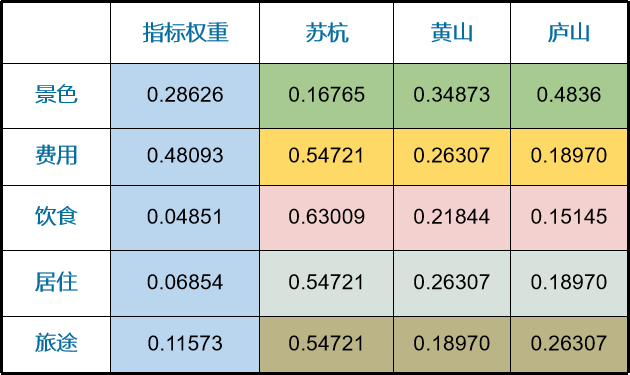

#### 4.3.4 计算最终得分

根据准则层的各准则（景色、费用、饮食、居住、旅途）对目标的权向量$W$和各方案对每一准则的权向量，将两个向量相乘得到最终的得分。

In [6]:
# 直接使用矩阵相乘W×P
result = W.dot(P)
result

array([0.44258285, 0.27694046, 0.28047669])

> *原稿配图未随 notebook 保存，此处暂缺。*

上述结果表明：方案1（苏杭）在旅游选择中占的权重为0.44256，接近0.5，远大于方案2（黄山权重为0.27692）、方案3（庐山权重为0.2805），因此，小明应该去苏杭。


### 4.4 理想解法（TOPSIS 原型）

> 来源：教材参考实现《数学建模算法与应用》14.1 节的练习稿（MIT，Zhanghan Wang），代码保持原样，仅按需改写数据路径并清空输出。

- 多属性决策方案集: $D=\{d_1,d_2,\cdots,d_m\}$
- 衡量方案优劣的属性变量: $x_1,x_2,\cdots,x_n$
- 每个方案属性向量: $[a_{i1},a_{i2},\cdots,a_{in}]$
- 正理想解$C^*$, 负理想解$C^0$
- 方案集中最优方案: 靠近正理想解又远离负理想解.

- TOPSIS法算法步骤在370页

## 5. 小结

本次实验通过一个具体的实例了解层次分析法每一步骤的具体思路和实施方法，其中包括判断矩阵的创建、判断矩阵的一致性检验和使用特征值法对一致性矩阵的权重求解。

通过本次实验需要掌握以下内容：
- 掌握 TOPSIS 法的基本思想与适用条件
- 掌握正负理想解与贴近度的计算步骤
- 掌握基于 Python 的 TOPSIS 实现
